<a href="https://colab.research.google.com/github/bforsbe/SK2534/blob/main/cryoem_exercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cryo-EM by the numbers: what does the archive tell you?

In this exercise you treat the **EMDB** (the Electron Microscopy Data Bank) as a dataset. You ask it questions, look at the trends, and then zoom in on one structure and compare it with what X-ray or NMR gave for the same protein. The point is to see in practice how the methods differ, not to get a "right" number.

| Part | What you do |
|---|---|
| Before you start | What does a "resolution" number mean in each method? |
| 1 | Download the EMDB table |
| 2 | Three guided questions: best of a year versus the trend, CCD versus direct detectors, size versus resolution |
| 3 | Take one record-setting entry into 3D |
| 4 | Find the same protein by X-ray or NMR and compare |
| 5 | Write your answers |

**How to use this notebook**

* You do not need to write code. Each step is one cell with a form: change the boxes, press the play button on the left of the cell, read the output.
* Run the **Setup** cell first, and run the rest in order. Do **not** use *Run all*, because some cells need your input.
* The code is hidden. Double-click a form cell title (or use the small arrow) if you are curious.
* If something stops working, use Runtime, then Restart session, and start again from Setup.
* The numbers come live from the EMDB. EMDB's own **[statistics page](https://www.ebi.ac.uk/emdb/statistics)** shows many of the same charts, so you can check yourself against it at the end.

## Setup
Run once (about 20 seconds).

In [1]:
#@title Setup (just run this cell) { display-mode: "form" }
!pip install -q py3Dmol
import io, re, requests, numpy as np, pandas as pd, py3Dmol
import matplotlib.pyplot as plt
from urllib.parse import quote
from concurrent.futures import ThreadPoolExecutor
from IPython.display import display, HTML

# ---- where data comes from -------------------------------------------------
EMDB_API = "https://www.ebi.ac.uk/emdb/api"
CORE     = "https://data.rcsb.org/rest/v1/core"
SEARCH   = "https://search.rcsb.org/rcsbsearch/v2/query"
FILES    = "https://files.rcsb.org/download"
SNAPSHOT_URL = ""        # instructor: URL of a saved CSV copy, used only if the live EMDB API is unreachable
FIELDS   = ["emdb_id", "structure_determination_method", "resolution", "release_date",
            "film_detector_category", "acceleration_voltage", "assembly_molecular_weight", "fitted_pdbs"]
EXTRA    = ["film_detector_model", "aggregation_state", "sample_main_name"]

STATE = {"raw": None, "tidy": None, "list": [], "current": None}     # what the notebook remembers

PALETTE = {"Direct detector": "#0072B2", "CCD": "#E69F00", "CMOS": "#009E73", "Film": "#7f7f7f", "Other/unknown": "#CC79A7"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})

# ---- 1. the EMDB table ------------------------------------------------------
def _first_number(s):
    return pd.to_numeric(s.astype(str).str.extract(r"(\d+\.?\d*)")[0], errors="coerce")

def _method(v):
    v = re.sub(r"[^a-z]", "", str(v).lower())
    for key, name in [("subtomogram", "subtomogram averaging"), ("tomography", "tomography"), ("single", "single particle"),
                      ("helical", "helical"), ("crystal", "2D/3D crystal")]:
        if key in v:
            return name
    return "other/unknown"

def _detector(v):
    v = str(v).lower()
    if "direct" in v or "ddd" in v: return "Direct detector"
    if "ccd" in v:                   return "CCD"
    if "cmos" in v:                  return "CMOS"
    if "film" in v or "plate" in v:  return "Film"
    return "Other/unknown"

def load_emdb(force=False):
    """Download one row per EMDB entry (a few MB, about 10 seconds) and tidy it."""
    if STATE["tidy"] is not None and not force:
        return STATE["tidy"]
    raw, err = None, None
    for fields in (FIELDS + EXTRA, FIELDS):
        try:
            r = requests.get(f"{EMDB_API}/search/{quote('*:*', safe='*:')}", timeout=300,
                             params={"rows": 1000000, "fl": ",".join(fields), "wt": "csv", "download": "false"})
            r.raise_for_status()
            raw = pd.read_csv(io.StringIO(r.text)); break
        except Exception as e:
            err = e
    if raw is None and SNAPSHOT_URL:
        raw = pd.read_csv(SNAPSHOT_URL)
    if raw is None:
        raise RuntimeError(f"Could not download the EMDB table ({err}). Tell your instructor.")
    d = pd.DataFrame({"emdb_id": raw["emdb_id"]})
    d["method"]     = raw["structure_determination_method"].map(_method) if "structure_determination_method" in raw else "other/unknown"
    d["resolution"] = pd.to_numeric(raw.get("resolution"), errors="coerce")
    d["year"]       = pd.to_datetime(raw.get("release_date"), errors="coerce", utc=True).dt.year
    d["detector"]   = raw["film_detector_category"].map(_detector) if "film_detector_category" in raw else "Other/unknown"
    d["voltage_kV"] = _first_number(raw["acceleration_voltage"]) if "acceleration_voltage" in raw else np.nan
    mass = _first_number(raw["assembly_molecular_weight"]) if "assembly_molecular_weight" in raw else pd.Series(np.nan, index=raw.index)
    d["mass_kDa"] = mass / 1000 if mass.median() > 20000 else mass         # EMDB gives Da or kDa; guess from the magnitude
    d["pdb"] = raw["fitted_pdbs"].astype(str).str.findall(r"\b[0-9][A-Za-z0-9]{3}\b").str[0].str.upper() if "fitted_pdbs" in raw else np.nan
    d["name"] = raw["sample_main_name"] if "sample_main_name" in raw else ""
    STATE["raw"], STATE["tidy"] = raw, d
    return d

def overview():
    d = load_emdb()
    print(f"{len(d):,} EMDB entries downloaded; {d['resolution'].notna().sum():,} have a resolution, "
          f"{d['pdb'].notna().sum():,} have a fitted model in the PDB, {d['mass_kDa'].notna().sum():,} have a molecular weight.")
    print(f"Mass column interpreted as kDa (median {d['mass_kDa'].median():,.0f}). Years covered: {int(d['year'].min())} to {int(d['year'].max())} "
          f"(the last year is incomplete).")
    display(d["method"].value_counts().rename("entries").to_frame().T)
    display(d["detector"].value_counts().rename("entries").to_frame().T)

def _subset(modality="single particle", y0=None, y1=None, need=("resolution",)):
    d = load_emdb()
    if modality != "all":
        d = d[d["method"] == modality]
    if y0: d = d[d["year"] >= y0]
    if y1: d = d[d["year"] <= y1]
    return d.dropna(subset=list(need))

def _remember(df):
    STATE["list"] = [i for i in df["emdb_id"]]

# ---- 2. the guided statistics tasks -------------------------------------------
def best_of_year(year=2022, n=5, modality="all"):
    """Task 1: best resolution released in one year, compared with the trend over time."""
    d = _subset(modality)
    ym = d.groupby("year")["resolution"]
    trend = pd.DataFrame({"best": ym.min(), "q25": ym.quantile(.25), "median": ym.median(), "q75": ym.quantile(.75), "n": ym.size()})
    top = d[d["year"] == year].nsmallest(n, "resolution")
    if top.empty:
        print("No entries that year for this selection."); return
    _remember(top)
    display(top[["emdb_id", "pdb", "resolution", "method", "detector", "mass_kDa", "name"]].reset_index(drop=True))
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.fill_between(trend.index, trend["q25"], trend["q75"], color="#9ecae1", alpha=.6, label="middle half of entries")
    ax.plot(trend.index, trend["median"], color="#0072B2", lw=2, label="median")
    ax.plot(trend.index, trend["best"], color="#444", lw=1.2, ls="--", label="best of the year")
    b = top.iloc[0]
    ax.scatter([year], [b["resolution"]], s=90, color="#D55E00", zorder=5, label=f"{b['emdb_id']} ({b['resolution']:.2f} Å)")
    ax.set(xlabel="release year", ylabel="resolution (Å), lower is better", title=f"Resolution over time ({modality}), best of {year} highlighted")
    ax.invert_yaxis(); ax.legend(frameon=False, fontsize=8)
    plt.tight_layout(); plt.show()
    t = trend.loc[year]
    print(f"{year}: {int(t['n']):,} entries. Best {t['best']:.2f} Å, median {t['median']:.2f} Å "
          f"(the record is {t['median'] - t['best']:.2f} Å better than the typical entry). "
          f"Best ever: {trend['best'].min():.2f} Å in {int(trend['best'].idxmin())}.")

def detector_trend(y0=2008, y1=2026, modality="single particle", only_overlap_years=False):
    """Task 2: CCD versus direct detectors."""
    d = _subset(modality, y0, y1)
    d = d[d["detector"].isin(["Direct detector", "CCD", "CMOS", "Film"])]
    if only_overlap_years:
        cnt = d.groupby(["year", "detector"]).size().unstack(fill_value=0)
        ok = cnt[(cnt.get("CCD", 0) >= 10) & (cnt.get("Direct detector", 0) >= 10)].index
        d = d[d["year"].isin(ok)]
        print("Only years with at least 10 CCD and 10 direct-detector entries:", [int(y) for y in ok])
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for det, g in d.groupby("detector"):
        per = g.groupby("year")["resolution"].agg(["median", "size"]); per = per[per["size"] >= 5]
        ax[0].plot(per.index, per["median"], marker="o", ms=3, color=PALETTE[det], label=det)
    ax[0].set(xlabel="release year", ylabel="median resolution (Å)", title="Median resolution per detector class"); ax[0].invert_yaxis(); ax[0].legend(frameon=False, fontsize=8)
    ax[0].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    use = d.groupby(["year", "detector"]).size().unstack(fill_value=0)
    use.plot.bar(stacked=True, ax=ax[1], color=[PALETTE[c] for c in use.columns], width=.85, legend=False)
    ax[1].set(xlabel="release year", ylabel="entries", title="Entries per year")
    plt.tight_layout(); plt.show()
    s = d.groupby("detector")["resolution"].agg(entries="size", best="min", median="median", q75=lambda x: x.quantile(.75)).round(2)
    display(s)

def size_vs_resolution(modality="single particle", y0=2015, y1=2026, log_x=True):
    """Task 3: does size matter?"""
    d = _subset(modality, y0, y1, need=("resolution", "mass_kDa"))
    d = d[d["mass_kDa"] > 0]
    if d.empty:
        print("No entries with both a molecular weight and a resolution."); return
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    ax.scatter(d["mass_kDa"], d["resolution"], s=5, alpha=.2, color="#0072B2", label="entries")
    bins = np.logspace(np.log10(d["mass_kDa"].min()), np.log10(d["mass_kDa"].max()), 14)
    g = d.groupby(pd.cut(d["mass_kDa"], bins), observed=True)["resolution"].agg(["median", "size"])
    g.index = [np.sqrt(iv.left * iv.right) for iv in g.index]       # bin centres on the log axis
    g = g[g["size"] >= 10]
    ax.plot(g.index, g["median"], color="#D55E00", lw=2.2, marker="o", label="median per size bin")
    if log_x: ax.set_xscale("log")
    ax.set(xlabel="assembly molecular weight (kDa)", ylabel="resolution (Å), lower is better", title=f"Resolution versus size ({modality}, {y0}-{y1})")
    ax.invert_yaxis(); ax.legend(frameon=False, fontsize=8)
    plt.tight_layout(); plt.show()
    rho = d["mass_kDa"].corr(d["resolution"], method="spearman")
    print(f"{len(d):,} entries (only those with a deposited model have a molecular weight). Spearman correlation: {rho:+.2f}")
    _remember(d.nsmallest(5, "resolution"))
    print("Five best-resolved in this plot (your list for Step 3):", ", ".join(STATE["list"]))

def explore(x="year", y="resolution", modality="single particle", y0=2008, y1=2026):
    """Task 4: your own question."""
    d = _subset(modality, y0, y1, need=(y, x))
    cats = {"detector", "method", "voltage_kV"}
    fig, ax = plt.subplots(figsize=(8, 4.4))
    if x in cats:
        order = d[x].value_counts().loc[lambda s: s >= 5].index.tolist()
        order = sorted(order) if x == "voltage_kV" else order
        ax.boxplot([d.loc[d[x] == o, y] for o in order], showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor="#9ecae1"), medianprops=dict(color="#D55E00", lw=2))
        ax.set_xticks(range(1, len(order) + 1), [f"{o}\n(n={int((d[x] == o).sum())})" for o in order], fontsize=8)
    else:
        ax.scatter(d[x], d[y], s=5, alpha=.2, color="#0072B2")
        if x == "mass_kDa": ax.set_xscale("log")
    ax.set(xlabel=x, ylabel=y, title=f"{y} versus {x} ({modality}, {y0}-{y1})")
    if y == "resolution": ax.invert_yaxis()
    plt.tight_layout(); plt.show()

# ---- 3. from a statistics row to a 3D structure -------------------------------------
def pdb_for(emdb_id=""):
    d = load_emdb()
    emdb_id = (emdb_id or "").strip().upper().replace("EMDB-", "EMD-")
    if emdb_id and not emdb_id.startswith("EMD-"):
        emdb_id = "EMD-" + emdb_id
    if not emdb_id:
        for cand in STATE["list"]:
            row = d[d["emdb_id"] == cand]
            if len(row) and isinstance(row.iloc[0]["pdb"], str):
                emdb_id = cand; break
        else:
            raise ValueError("None of the entries from your last task has a model in the PDB. Pick one by typing its EMDB ID.")
    row = d[d["emdb_id"] == emdb_id]
    if row.empty:
        raise ValueError(f"{emdb_id} is not in the table.")
    row = row.iloc[0]
    print(f"{emdb_id}: {row['method']}, {row['resolution']} Å, detector {row['detector']}, {row['name']}")
    if not isinstance(row["pdb"], str):
        raise ValueError(f"{emdb_id} has a map but no deposited model in the PDB, so there is nothing to show in 3D. "
                         f"Look at the map on its EMDB page: https://www.ebi.ac.uk/emdb/{emdb_id}")
    return row["pdb"]

def card(pdb_id):
    pdb_id = pdb_id.upper()
    r = requests.get(f"{CORE}/entry/{pdb_id}", timeout=30); r.raise_for_status(); d = r.json()
    info, ids = d.get("rcsb_entry_info", {}), d.get("rcsb_entry_container_identifiers", {})
    first = lambda x: (x[0] if x else {}) if isinstance(x, list) else (x or {})
    rec, img = first(d.get("em_3d_reconstruction")), first(d.get("em_imaging"))
    res = rec.get("resolution") or (info.get("resolution_combined") or [None])[0]
    return {"PDB": pdb_id, "EMDB": ", ".join(ids.get("emdb_ids") or []) or "-", "method": info.get("experimental_method"),
            "resolution (A)": res, "mass (kDa)": round(info["molecular_weight"]) if info.get("molecular_weight") else None,
            "particles": rec.get("num_particles"), "symmetry": rec.get("point_symmetry") or rec.get("symmetry_type"),
            "kV": img.get("accelerating_voltage"), "atoms": info.get("deposited_atom_count"),
            "chains": info.get("deposited_polymer_entity_instance_count"), "title": (d.get("struct", {}).get("title") or "")[:60]}

def cards(ids):
    def safe(i):
        try: return card(i)
        except Exception as e: return {"PDB": i, "title": f"(could not read entry: {e})"}
    with ThreadPoolExecutor(8) as ex:
        return pd.DataFrame(list(ex.map(safe, ids)))

def _post(query):
    r = requests.post(SEARCH, json=query, timeout=60)
    if r.status_code == 204: return 0, []
    if r.status_code != 200: raise RuntimeError(f"Search failed (HTTP {r.status_code}): {r.text[:300]}")
    j = r.json(); return j.get("total_count", 0), [h["identifier"] for h in j["result_set"]]

def cif_url(pdb_id, assembly=None):
    pdb_id = pdb_id.upper()
    return f"{FILES}/{pdb_id}-assembly{assembly}.cif" if assembly else f"{FILES}/{pdb_id}.cif"

def _exists(url):
    try:
        r = requests.get(url, stream=True, timeout=30); ok = r.status_code == 200; r.close(); return ok
    except Exception:
        return False

def _url(pdb_id, assembly):
    if assembly and _exists(cif_url(pdb_id, 1)): return cif_url(pdb_id, 1)
    if assembly: print(f"{pdb_id}: no pre-built assembly, showing the deposited coordinates.")
    return cif_url(pdb_id)

def resolve(pdb_id):
    pdb_id = (pdb_id or "").strip().upper()
    if pdb_id: return pdb_id
    if STATE["current"]: return STATE["current"]
    raise ValueError("No entry yet. Run Step 3 first, or type a PDB ID.")

def _b_range(text, lo=5, hi=95):
    hdr, vals, idx = [], [], None
    for ln in text.splitlines():
        if ln.startswith("_atom_site."): hdr.append(ln.split()[0])
        elif hdr and ln.startswith(("ATOM", "HETATM")):
            idx = hdr.index("_atom_site.B_iso_or_equiv") if idx is None else idx
            try: vals.append(float(ln.split()[idx]))
            except (ValueError, IndexError): pass
    return float(np.percentile(vals, lo)), float(np.percentile(vals, hi))

def _style(v, colour, text=None, viewer=None):
    kw = {} if viewer is None else {"viewer": viewer}
    if colour == "b-factor":
        lo, hi = _b_range(text) if text else (0, 100)
        v.setStyle({"cartoon": {"colorscheme": {"prop": "b", "gradient": "roygb", "min": lo, "max": hi}}}, **kw)
        print(f"Colour scale: B-factor column from {lo:.0f} (red) to {hi:.0f} (blue). Check what this column means for this entry!")
    elif colour == "spectrum": v.setStyle({"cartoon": {"color": "spectrum"}}, **kw)
    else: v.setStyle({"cartoon": {"colorscheme": "chain"}}, **kw)

def links(pdb_id, emdb):
    pid = pdb_id.lower()
    parts = [f'<a target="_blank" href="https://www.rcsb.org/structure/{pdb_id}">RCSB page</a>',
             f'<a target="_blank" href="https://files.wwpdb.org/pub/pdb/validation_reports/{pid[1:3]}/{pid}/{pid}_validation.pdf">validation report (PDF)</a>']
    for e in (emdb or "").split(", "):
        if e.startswith("EMD-"):
            parts.insert(0, f'<a target="_blank" href="https://www.ebi.ac.uk/emdb/{e}">EMDB {e} (map, FSC, local resolution)</a>')
    display(HTML(" &nbsp;|&nbsp; ".join(parts)))

def look(emdb_or_pdb="", assembly=True, colour="chain", width=750, height=520):
    """Blank = the best entry from your last task that has a model. Accepts an EMDB ID or a PDB ID."""
    s = (emdb_or_pdb or "").strip()
    pdb_id = pdb_for(s) if (not s or s.upper().startswith(("EMD", "EMDB")) or s.isdigit()) else s.upper()
    STATE["current"] = pdb_id
    c = card(pdb_id)
    display(pd.DataFrame([c]).T.rename(columns={0: pdb_id}))
    links(pdb_id, c["EMDB"])
    url = _url(pdb_id, assembly)
    text = requests.get(url, timeout=120).text if colour == "b-factor" else None
    v = py3Dmol.view(query=f"url:{url}", width=width, height=height)
    _style(v, colour, text); v.zoomTo()
    return v

def find_related(pdb_id="", entity=1, identity=0.9, n=15):
    """Other entries with the same protein (sequence identity >= 90%) solved by X-ray or NMR."""
    pdb_id = resolve(pdb_id)
    r = requests.get(f"{CORE}/polymer_entity/{pdb_id}/{entity}", timeout=30); r.raise_for_status(); e = r.json()
    poly = e["entity_poly"]; seq = poly["pdbx_seq_one_letter_can"]
    kind = {"protein": "protein", "dna": "dna", "rna": "rna"}.get(poly.get("rcsb_entity_polymer_type", "").lower())
    print(f"Entity {entity} of {pdb_id}: {e.get('rcsb_polymer_entity', {}).get('pdbx_description')} ({len(seq)} residues). Change 'entity' to follow another chain type.")
    if not kind: raise ValueError("This entity is not a protein, DNA or RNA chain; try another entity number.")
    query = {"query": {"type": "group", "logical_operator": "and", "nodes": [
                {"type": "terminal", "service": "sequence", "parameters": {"evalue_cutoff": 1, "identity_cutoff": identity, "sequence_type": kind, "value": seq}},
                {"type": "terminal", "service": "text", "parameters": {"attribute": "exptl.method", "operator": "in", "value": ["X-RAY DIFFRACTION", "SOLUTION NMR"]}}]},
             "return_type": "entry", "request_options": {"paginate": {"start": 0, "rows": n}}}
    total, ids = _post(query)
    print(f"{total} X-ray/NMR entries with this sequence, showing {len(ids)}.")
    if not ids: return None
    df = cards(ids).sort_values(["method", "resolution (A)"])
    display(df[["PDB", "method", "resolution (A)", "mass (kDa)", "atoms", "chains", "title"]])
    return df

def look_pair(left="", right="", assembly=True, colour="chain", width=950, height=450):
    left = resolve(left); right = (right or "").strip().upper()
    if not right: raise ValueError("Type a second PDB ID (for example one from Step 3) in 'right'.")
    v = py3Dmol.view(width=width, height=height, viewergrid=(1, 2), linked=True)
    for col, pid in enumerate([left, right]):
        text = requests.get(_url(pid, assembly), timeout=120).text
        v.addModel(text, "cif", viewer=(0, col)); _style(v, colour, text, viewer=(0, col)); v.zoomTo(viewer=(0, col))
    print(f"left: {left}   right: {right}")
    return v

# ---- 4. explanatory figures (schematics, not data) ------------------------------------
def fig_archives():
    """How EMPIAR, EMDB and the PDB relate."""
    fig, ax = plt.subplots(figsize=(10, 3.4)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 3.4)
    from matplotlib.patches import FancyBboxPatch
    boxes = [(0.15, "EMPIAR", "raw images\n(movies, particle stacks)", "#E3E9EF"),
             (3.55, "EMDB", "3D map, half-maps, masks\n+ metadata: resolution, detector,\nvoltage, year ...", "#9ecae1"),
             (6.95, "PDB", "atomic model\n(coordinates)", "#F6D9A8")]
    for x, title, body, col in boxes:
        ax.add_patch(FancyBboxPatch((x, 1.35), 2.9, 1.75, boxstyle="round,pad=0.03", fc=col, ec="#444", lw=1))
        ax.text(x + 1.45, 2.85, title, ha="center", va="center", fontweight="bold", fontsize=12)
        ax.text(x + 1.45, 2.05, body, ha="center", va="center", fontsize=9)
    for x0, x1, lab in [(3.1, 3.5, ""), (6.5, 6.9, "")]:
        ax.annotate("", xy=(x1, 2.2), xytext=(x0, 2.2), arrowprops=dict(arrowstyle="->", lw=1.6))
    ax.text(3.3, 0.95, "image processing", ha="center", fontsize=8.5, style="italic")
    ax.text(6.7, 0.8, "model building\n(not always done)", ha="center", fontsize=8.5, style="italic")
    ax.text(5, 0.05, "In this exercise: statistics come from EMDB  ->  the field 'fitted_pdbs' links an entry to its PDB model  ->  the 3D view loads the PDB file.\n"
                     "An entry with a map but no model stops at EMDB, and is missing from every plot that needs a molecular weight.",
            ha="center", va="center", fontsize=8.5)
    plt.tight_layout(); plt.show()

def fig_fsc():
    """What the resolution number is, schematically."""
    f = np.linspace(0, 0.5, 400)
    def fsc(fc):                                    # smooth curve that crosses 0.143 exactly at fc
        f0 = fc / 6 ** (1 / 8)
        return 1 / (1 + (f / f0) ** 8)
    fig, ax = plt.subplots(figsize=(7.6, 3.9))
    for fc, col, lab in [(1 / 3.0, "#0072B2", "map A"), (1 / 6.0, "#D55E00", "map B")]:
        ax.plot(f, fsc(fc), color=col, lw=2.2, label=lab)
        ax.plot([fc, fc], [0, 0.143], color=col, ls=":", lw=1.4)
        ax.annotate(f"resolution {1 / fc:.0f} Å", xy=(fc, 0.143), xytext=(fc + 0.02, 0.33 if fc > 0.2 else 0.5), color=col,
                    arrowprops=dict(arrowstyle="->", color=col), fontsize=9)
    ax.axhline(0.143, color="#444", ls="--", lw=1); ax.text(0.5, 0.16, "FSC = 0.143", ha="right", fontsize=8.5)
    ax.set_xticks([0, 0.1, 0.2, 1 / 3, 0.5], ["0", "10 Å", "5 Å", "3 Å", "2 Å"])
    ax.set(xlabel="spatial frequency (finer detail to the right)", ylabel="FSC between two half-maps", ylim=(0, 1.05),
           title="Schematic: where the correlation between two independent half-maps drops below 0.143")
    ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 0.9))
    plt.tight_layout(); plt.show()

def fig_symmetry():
    """Why symmetric particles are easy."""
    names, copies = ["C1 (none)", "C2", "C3", "D2", "D3", "T (tetrahedral)", "O (octahedral)", "I (icosahedral)"], [1, 2, 3, 4, 6, 12, 24, 60]
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.barh(names[::-1], copies[::-1], color="#0072B2")
    for y, c in enumerate(copies[::-1]):
        ax.text(c + 0.8, y, str(c), va="center", fontsize=9)
    ax.set(xlabel="copies of the asymmetric unit in every particle image", title="Symmetry multiplies your data (one particle image counts many times)")
    ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

# ---- the blur toy: a few atoms, blurred by a B-factor and a resolution limit ------------------
_RING  = [(1.4 * np.cos(a), 1.4 * np.sin(a)) for a in np.arange(6) * np.pi / 3]      # six atoms, 1.4 A apart
_ATOMS = _RING + [(2.8, 0.0), (3.9, 0.9)]                                              # plus a short tail
_WATER = [(-4.0, -2.2)]
_N, _L = 256, 14.0
_pix = _L / _N
_xs = (np.arange(_N) - _N / 2) * _pix
_X, _Y = np.meshgrid(_xs, _xs)
_k = np.fft.fftfreq(_N, d=_pix); _KX, _KY = np.meshgrid(_k, _k); _K2 = _KX ** 2 + _KY ** 2; _K = np.sqrt(_K2)
_g = lambda x, y: np.exp(-((_X - x) ** 2 + (_Y - y) ** 2) / (2 * 0.2 ** 2))
_F0 = np.fft.fft2(sum(_g(*a) for a in _ATOMS) + 0.7 * sum(_g(*w) for w in _WATER))

def blur_map(B, res):
    """Damp the fine detail by exp(-B s^2/4) (s = 1/d) and cut it off at the resolution limit."""
    return np.real(np.fft.ifft2(_F0 * np.exp(-B * _K2 / 4) / (1 + (_K * res) ** 16)))

def _dip(B, res):
    """Density halfway between two neighbouring ring atoms, relative to the lower of the two atom peaks."""
    m = blur_map(B, res); at = lambda x, y: m[int(round(y / _pix + _N / 2)), int(round(x / _pix + _N / 2))]
    (x0, y0), (x1, y1) = _RING[0], _RING[1]
    return at((x0 + x1) / 2, (y0 + y1) / 2) / min(at(x0, y0), at(x1, y1))

def _draw_pair(B, res):
    fig, ax = plt.subplots(1, 2, figsize=(8, 3.9))
    for x, y in _ATOMS: ax[0].scatter([x], [y], s=260, color="#444")
    for x, y in _WATER: ax[0].scatter([x], [y], s=180, color="#0072B2")
    for i in range(6): ax[0].plot(*zip(_RING[i], _RING[(i + 1) % 6]), color="#444", lw=2)
    ax[0].plot([_RING[0][0] * 2, 2.8, 3.9], [0, 0, 0.9], color="#444", lw=2)
    ax[0].set(xlim=(-6, 6), ylim=(-6, 6), title="the atoms (what is really there)"); ax[0].set_aspect("equal")
    m = blur_map(B, res)
    ax[1].imshow(np.clip(m, 0, None), origin="lower", extent=(-7, 7, -7, 7), cmap="Blues", vmin=0)
    ax[1].set(title=f"the map: B = {B:g} Å², resolution = {res:g} Å")
    for a in ax: a.set_xticks([]); a.set_yticks([]); a.grid(False)
    fig.text(0.5, 0.02, f"B = {B:g} Å² means each atom is smeared by about {np.sqrt(B / (8 * np.pi ** 2)):.2f} Å (rms). Map scaled to its own maximum.",
             ha="center", fontsize=8.5)
    plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

def fig_blur():
    """Static preview: B = 20 A^2, five resolution limits."""
    fig, axes = plt.subplots(1, 5, figsize=(12, 2.9))
    for ax, r in zip(axes, [1.0, 1.5, 2.5, 4.0, 6.0]):
        m = blur_map(20, r)
        ax.imshow(np.clip(m, 0, None), origin="lower", extent=(-7, 7, -7, 7), cmap="Blues", vmin=0)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.set_title(f"{r:g} Å", fontsize=11)
    fig.suptitle("Preview: the same atoms with B = 20 Å² at five resolution limits. Run the cell below to move the sliders yourself.", fontsize=10, y=1.0)
    plt.tight_layout(); plt.show()

def blur_explorer():
    """Two sliders: B-factor and resolution."""
    try:
        from ipywidgets import interact, FloatSlider
    except ImportError:
        fig_blur(); return
    st = {"description_width": "110px"}
    interact(_draw_pair,
             B=FloatSlider(value=20, min=0, max=120, step=5, description="B-factor (Å²)", style=st, layout={"width": "420px"}),
             res=FloatSlider(value=3.0, min=0.8, max=6.0, step=0.1, description="resolution (Å)", style=st, layout={"width": "420px"}))

def _separated(B, res):
    """Neighbouring atoms count as separated if the valley between them is at least 10% deep at this resolution
    and at every finer one (this ignores accidental dips caused by ripples from a hard resolution cut-off)."""
    return all(_dip(B, r) < 0.9 for r in np.arange(0.8, max(res, 0.8) + 1e-9, 0.1))

def reveal_blur(B, res):
    """Compare the student's guess of 'atomic' with where two neighbouring atoms really separate."""
    if "sep" not in STATE:
        Rg, Bg = np.round(np.arange(0.8, 4.01, 0.1), 1), np.arange(0, 100.1, 5)
        dip = np.array([[_dip(b, r) for r in Rg] for b in Bg])
        STATE["sep"] = (Rg, Bg, np.cumprod(dip < 0.9, axis=1))      # separated here and at every finer resolution
    Rg, Bg, M = STATE["sep"]
    ok = _separated(B, res)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
    ax[0].contourf(Rg, Bg, M, levels=[-0.5, 0.5, 1.5], colors=["#f0f0f0", "#bde0c6"])
    ax[0].contour(Rg, Bg, M, levels=[0.5], colors=["#2a7a46"], linewidths=1.5)
    ax[0].axvline(1.2, color="#444", ls="--", lw=1); ax[0].text(1.22, 97, "1.2 Å", fontsize=8, va="top")
    ax[0].scatter([res], [B], marker="*", s=260, color="#D55E00", edgecolor="k", zorder=5, label="your answer")
    ax[0].annotate("neighbouring atoms\nseparated", xy=(1.32, 15), xytext=(2.4, 33), fontsize=9, color="#2a7a46",
                   arrowprops=dict(arrowstyle="->", color="#2a7a46"))
    ax[0].text(3.0, 70, "atoms merged", fontsize=9, color="#555")
    ax[0].set(xlabel="resolution (Å), finer to the right", ylabel="B-factor (Å²)", xlim=(4.0, 0.8), ylim=(0, 100),
              title="Can you tell two neighbouring atoms (1.4 Å apart) apart?")
    ax[0].legend(frameon=False, loc="upper left", fontsize=8)
    ax[1].imshow(np.clip(blur_map(B, res), 0, None), origin="lower", extent=(-7, 7, -7, 7), cmap="Blues", vmin=0)
    ax[1].set_xticks([]); ax[1].set_yticks([]); ax[1].grid(False); ax[1].set(title=f"your map: B = {B:g} Å², {res:g} Å")
    plt.tight_layout(); plt.show()
    print("With your numbers the neighbouring atoms ARE separated." if ok else
          "With your numbers the neighbouring atoms are merged: you could not call this atomic.")
    print("\nCrystallographers call data 'atomic resolution' when they reach about 1.2 Å or better, where individual atoms separate. "
          "Cryo-EM papers often say 'near-atomic' for 3 to 4 Å, where you can trace the chain and build an atomic model but individual atoms are not separated. "
          "Notice that a high B-factor ruins it however good the resolution is. Which usage does your answer match?")

print("Ready.")

Ready.


## Before you start: what does "resolution" mean?

You will compare resolution numbers all through this exercise, so first agree on what they are. The three methods measure different things and do not report the same quantity.

| | X-ray crystallography | Cryo-EM | NMR |
|---|---|---|---|
| **Sample** | a crystal, usually cooled | molecules frozen in thin glassy ice | molecules in solution |
| **What is recorded** | diffraction spots | many 2D projection images of single particles | nuclear spin interactions |
| **Result** | electron density map | Coulomb potential map (electrostatic potential) | distance and angle restraints, giving an *ensemble* of models |
| **"Resolution" is** | the diffraction limit (d<sub>min</sub>): how far out the spots can be measured | where the correlation between two independent half-maps (the **FSC**) drops below a threshold, usually **0.143** | not defined; precision is the spread of the ensemble |
| **How you validate** | R-free, geometry | FSC, map-model fit, Q-score, geometry | restraint violations, ensemble spread |
| **Roughly, what size works** | anything that crystallises | from tens of kDa up, with no real upper limit | up to a few tens of kDa routinely |

Two things to keep in mind:

* In cryo-EM the number is a **global average**. Parts of a map, often the periphery or flexible domains, are usually worse than the headline number. The EMDB entry page shows a local resolution map.
* "3.2 Å" in a crystal structure and "3.2 Å" in a cryo-EM map are not the same statement, even if they happen to look similar on screen. Keep that in mind when you compare methods in Part 4.

The EMDB field `resolution` that you will use is the best resolution reported among the reconstructions of an entry.

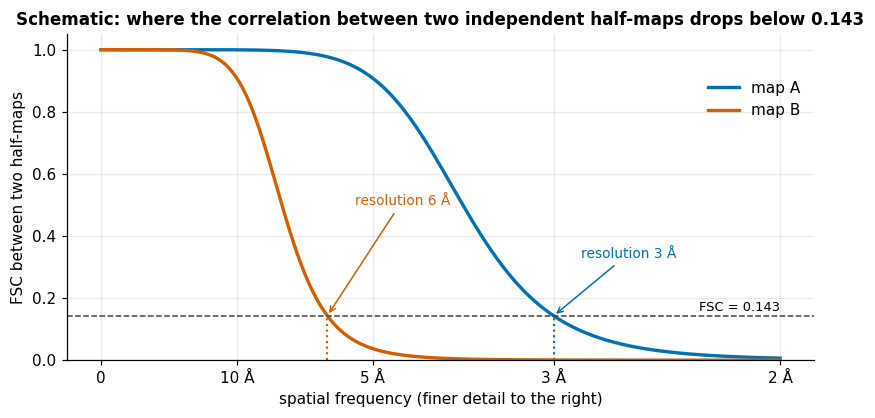

In [2]:
#@title Figure 1 · Resolution from the FSC (schematic) { display-mode: "form" }
fig_fsc()

*Figure 1. The map is reconstructed twice from two independent halves of the data. The two half-maps agree at coarse detail and disagree at fine detail, because noise takes over. The resolution is read off where agreement falls below 0.143. Map A reaches finer detail than map B. This is a schematic, not real data.*

## Part 1: Get the data

Three archives work together:

* **EMPIAR** holds the raw images. Few entries have them deposited.
* **EMDB** holds the 3D maps and the metadata about how they were made (resolution, microscope settings, year, and so on). This is where your statistics come from.
* **The PDB** holds atomic models. Many EMDB entries have a model fitted into the map, and the EMDB records its PDB code. That link is how you will go from a row in a table to a 3D picture.

Some entries have a map but no model, and those cannot be shown as a structure in Part 3.

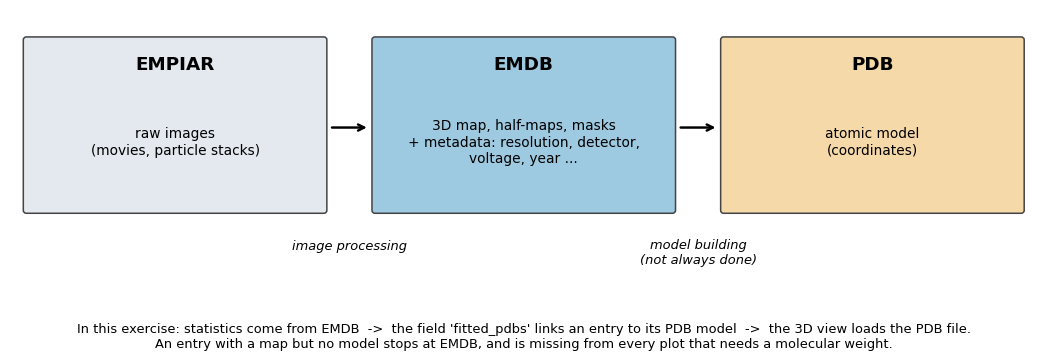

In [3]:
#@title Figure 2 · The three archives (schematic) { display-mode: "form" }
fig_archives()

One row per EMDB entry is downloaded next. Run it, then read the summary: how many entries there are, how many have a model in the PDB, and how many have a molecular weight. Those counts matter later.

In [4]:
#@title Part 1 · Download the EMDB table { display-mode: "form" }
overview()

/tmp/ipykernel_498/2309574792.py:55: DtypeWarning: Columns (3,5) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.read_csv(io.StringIO(r.text)); break


83,829 EMDB entries downloaded; 61,708 have a resolution, 37,166 have a fitted model in the PDB, 36,461 have a molecular weight.
Mass column interpreted as kDa (median 313). Years covered: 2002 to 2026 (the last year is incomplete).


method,single particle,other/unknown,subtomogram averaging,tomography,helical,2D/3D crystal
entries,54283,20022,3526,2998,2804,196


detector,Other/unknown,CCD,Film
entries,80174,2550,1105


## Part 2: Three questions for the archive

### Question 1: How good is the best structure of a year, compared with everybody else?

Records are exciting, but they are only meaningful against the background. This plot puts the best entry of a year next to the median and the middle half of all entries from the same year.

Two things to know before you run it:

* Resolution is plotted upside down, so that *better is higher*.
* Record-setting entries are often **test specimens**: very stable, rigid, often highly symmetric proteins that groups use to push the limits of hardware and software, rather than to answer a biological question. Apoferritin is the classic one.

Start with 2022, then try a few other years. Look at the highlighted entry and at what it is a structure of.

,emdb_id,pdb,resolution,method,detector,mass_kDa,name
0,EMD-24079,NaN,0.60,2D/3D crystal,Other/unknown,NaN,Carbamazepine
1,EMD-31314,NaN,1.29,single particle,Other/unknown,NaN,Apoferritin
2,EMD-28742,NaN,1.42,single particle,Other/unknown,NaN,Apoferritin
3,EMD-15619,NaN,1.47,single particle,Other/unknown,NaN,Mouse heavy-chain apoferritin
4,EMD-33707,NaN,1.47,single particle,Other/unknown,NaN,Apoferritin


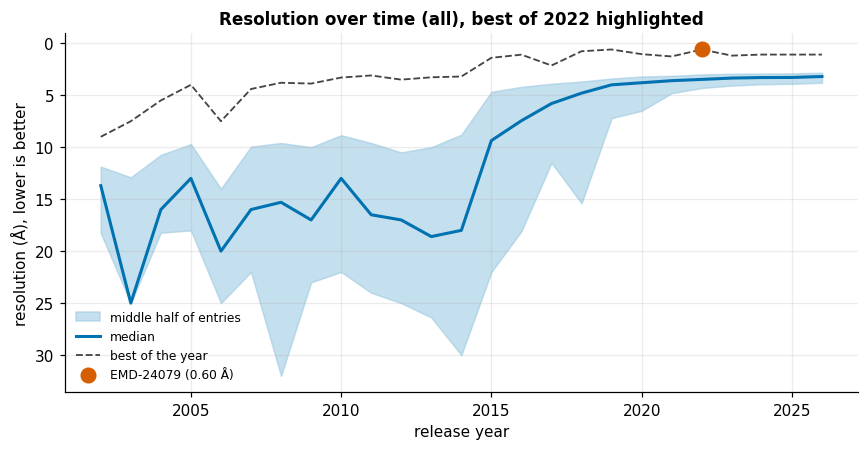

2022: 5,881 entries. Best 0.60 Å, median 3.48 Å (the record is 2.88 Å better than the typical entry). Best ever: 0.60 Å in 2019.


In [5]:
#@title Task 1 · Best of a year versus the trend { display-mode: "form" }
year = 2022 #@param {type:"slider", min:2010, max:2026, step:1}
how_many = 5 #@param {type:"slider", min:3, max:15, step:1}
modality = "all" #@param ["all", "single particle", "helical", "tomography", "subtomogram averaging"]
best_of_year(year, how_many, modality)

### Question 2: Did direct detectors really change the field?

Every cryo-EM image begins as electrons landing on a camera, and the camera was one of the big changes in the last decade.

* **CCD (indirect detection).** Electrons hit a layer that converts each one into a flash of light, and the light is passed on to a CCD chip. The flash spreads out, which blurs fine detail and adds noise. Readout is slow, so an exposure is essentially a single image.
* **Direct electron detector.** A thin silicon sensor registers the electrons themselves, with much less blurring. Readout is fast, so one exposure becomes a **movie** of many frames. Software aligns the frames and removes the motion of the sample caused by the beam, which was a major limit before. Some detectors can even count single electrons.

A camera is judged by its **DQE** (detective quantum efficiency): how much of the signal at each spatial frequency survives the camera. Direct detectors keep far more of the fine detail. They arrived in routine use around 2012 to 2013, and the years after are often called the *resolution revolution*.

The figure below, from the MyScope training platform, illustrates detection in the electron microscope. Use it together with the description above.

<img src="https://myscope.training/images/CRYO-module/figure_23.jpg" alt="Figure from the MyScope cryo-EM training module on electron detection" width="650">

*Figure 3. Image: MyScope training platform (Microscopy Australia), cryo-EM module, [myscope.training](https://myscope.training). If the image does not load, open the link and look for the section on detectors.*

**Be careful with the comparison.** The detector is one change among several. Over the same years there were also better microscopes and automated data collection, new classification and refinement software, and improved sample preparation. A difference between CCD and direct detectors in your plot is therefore **not purely the camera**. That is the reason for the *only_overlap_years* tick: it keeps only the years where both detector types were in real use, so that time itself is no longer the main difference.

The EMDB stores the detector category as entered by the depositor, so the classes are approximate. A label such as "CMOS" may hide a direct detector.

Run it once as it is. Then tick *only_overlap_years* and run it again.

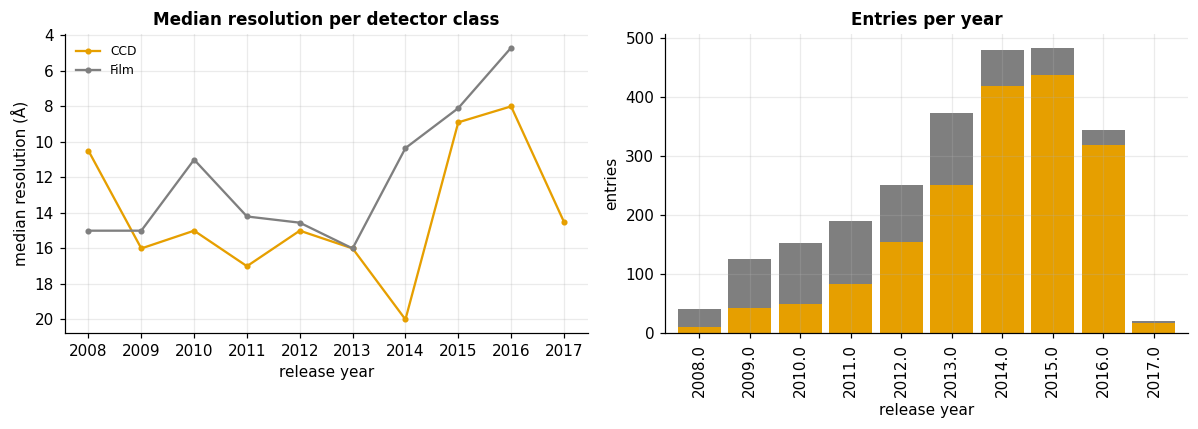

,entries,best,median,q75
detector,,,,
CCD,1781,2.2,13.7,22.0
Film,675,2.9,13.0,20.0


In [6]:
#@title Task 2 · CCD versus direct detectors { display-mode: "form" }
first_year = 2008 #@param {type:"slider", min:2002, max:2026, step:1}
last_year = 2026 #@param {type:"slider", min:2002, max:2026, step:1}
modality = "single particle" #@param ["single particle", "all", "helical", "tomography", "subtomogram averaging"]
only_overlap_years = False #@param {type:"boolean"}
detector_trend(first_year, last_year, modality, only_overlap_years)

### Question 3: Does size matter?

In cryo-EM the signal of a single particle grows with its mass, so a small particle gives faint, noisy images that are hard to align. That suggests that bigger is easier. But there is a competing effect:

* **Symmetry multiplies your data.** If a particle has 24 identical subunits arranged with octahedral symmetry, every image of it contains 24 copies of the same thing to average. Large symmetric assemblies are therefore the easy case, and many benchmark samples are of this kind.
* **Big complexes tend to be flexible.** Moving parts blur the average, which can push resolution the other way.

Compare this with the other methods. For X-ray, size matters little; what matters is whether the molecule forms a well-ordered crystal. For NMR, size is the hard limit.

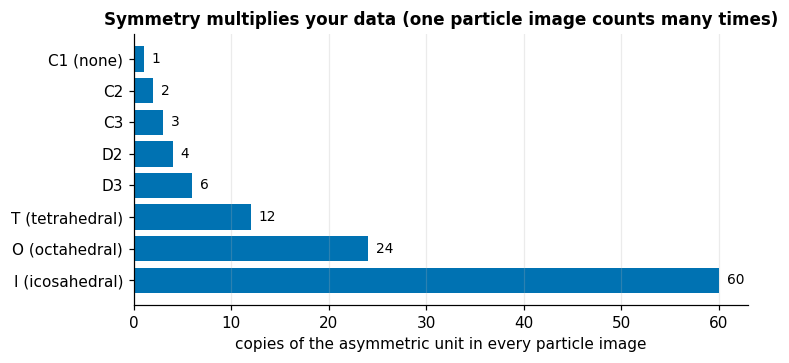

In [7]:
#@title Figure 4 · Symmetry and the amount of data (schematic) { display-mode: "form" }
fig_symmetry()

*Figure 4. The number of identical copies of the asymmetric unit contained in one particle, for the common symmetry groups. Real data are also limited by how well the particles can be aligned.*

Decide what you expect to see before you press play. Each dot below is an entry, and the orange line is the median per size bin. Change the years and the method, and watch what happens to the picture. Note the count printed under the plot: only entries with a model deposited in the PDB have a molecular weight.

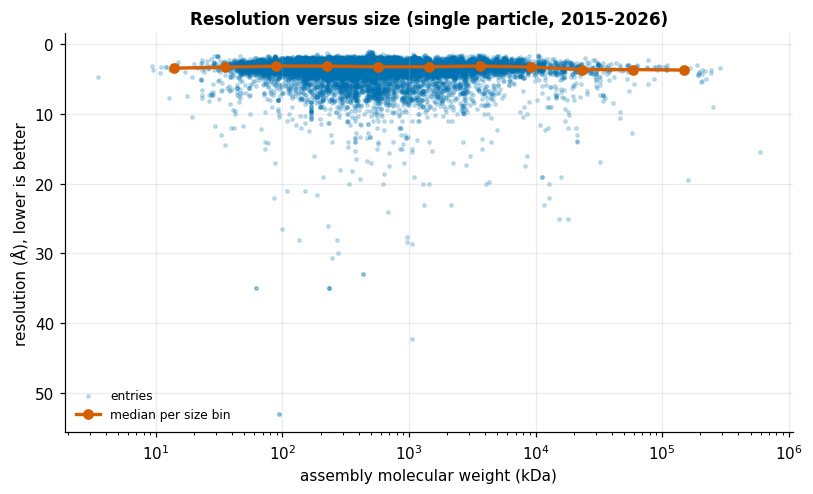

33,220 entries (only those with a deposited model have a molecular weight). Spearman correlation: +0.06
Five best-resolved in this plot (your list for Step 3): EMD-19436, EMD-11668, EMD-35984, EMD-11638, EMD-68251


In [8]:
#@title Task 3 · Size versus resolution { display-mode: "form" }
first_year = 2015 #@param {type:"slider", min:2002, max:2026, step:1}
last_year = 2026 #@param {type:"slider", min:2002, max:2026, step:1}
modality = "single particle" #@param ["single particle", "all", "helical", "tomography", "subtomogram averaging"]
log_x_axis = True #@param {type:"boolean"}
size_vs_resolution(modality, first_year, last_year, log_x_axis)

### Your own question (optional, but this is where it gets interesting)

Pick what goes on the horizontal axis and what on the vertical. Some ideas:

* **Voltage.** Most high-resolution work is done at 300 kV. Many labs run 200 kV microscopes, which are cheaper. Does the plot show a difference, and is voltage really the cause?
* **Method.** Helical and tomography entries are different kinds of experiments, so a comparison with single particle is a comparison of methods, not of quality.
* **Year against size.** Are the new records also the big or small ones?

Decide what you expect before you press play.

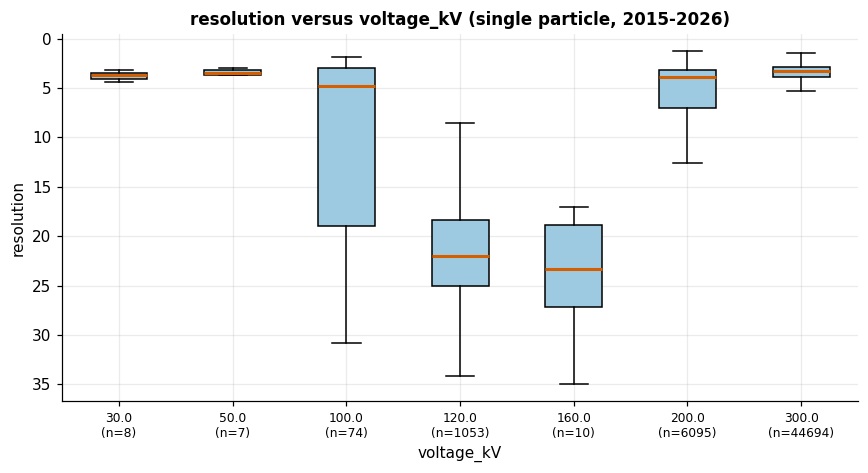

In [9]:
#@title Task 4 · Your own question { display-mode: "form" }
x_axis = "voltage_kV" #@param ["year", "mass_kDa", "voltage_kV", "detector", "method"]
y_axis = "resolution" #@param ["resolution", "mass_kDa", "year"]
modality = "single particle" #@param ["single particle", "all", "helical", "tomography", "subtomogram averaging"]
first_year = 2015 #@param {type:"slider", min:2002, max:2026, step:1}
last_year = 2026 #@param {type:"slider", min:2002, max:2026, step:1}
explore(x_axis, y_axis, modality, first_year, last_year)

## Part 3: Take one entry into 3D

Statistics tell you what is typical. Now look at one extreme. First, a question that every method has to answer: **what does "atomic" resolution actually mean?**

### Two ways to blur an atom

A map never shows an atom as a sharp point. Two different things blur it, and they are easy to mix up.

* **Resolution** is how much fine detail the data contain at all. Throw away the finest detail and every atom smears out.
* **The B-factor** (atomic displacement parameter) describes how much each atom is smeared by motion and disorder in the sample. A B of 20 Å² means the atom is smeared by about 0.5 Å (rms). The fine detail is damped by exp(−B s² / 4), where s is one over the resolution.

Both end up as the same kind of blur, so a flexible, disordered molecule looks poor even when the data reach far. Cryo-EM uses the same formula on purpose, with a *negative* B, to **sharpen** a map.

The toy below is a small group of atoms (a six-membered ring, a short tail and a water molecule). It is a 2D picture, not a real map. Run the cell and move the two sliders.

In [10]:
#@title Figure 5 · Blur an atom with B-factor and resolution { display-mode: "form" }
blur_explorer()

interactive(children=(FloatSlider(value=20.0, description='B-factor (Å²)', layout=Layout(width='420px'), max=1…

**Your task.** Move the sliders until you would be happy to say *"I can see the individual atoms"*. Look especially at the six ring atoms, which are only 1.4 Å apart. Which B-factor and which resolution does that need? Write your two numbers in the cell below. It then shows how your answer compares with where neighbouring atoms really separate.

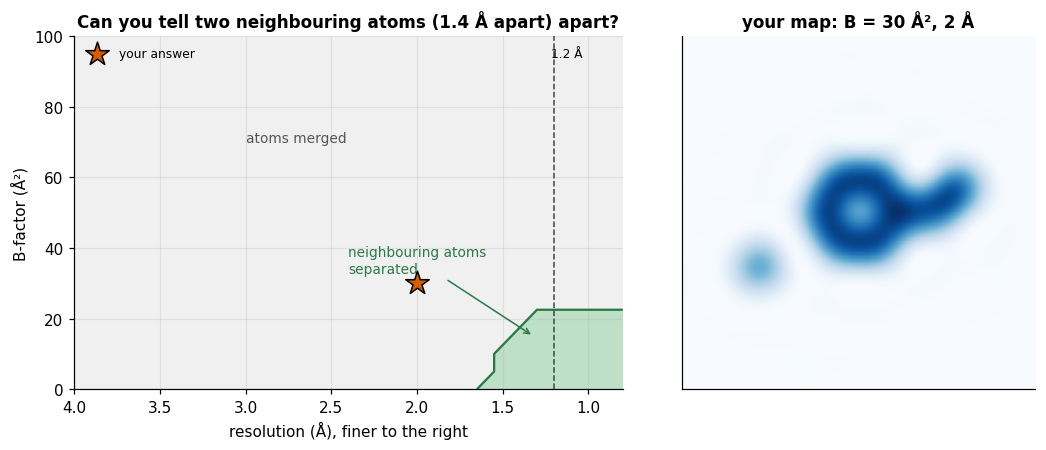

With your numbers the neighbouring atoms are merged: you could not call this atomic.

Crystallographers call data 'atomic resolution' when they reach about 1.2 Å or better, where individual atoms separate. Cryo-EM papers often say 'near-atomic' for 3 to 4 Å, where you can trace the chain and build an atomic model but individual atoms are not separated. Notice that a high B-factor ruins it however good the resolution is. Which usage does your answer match?


In [11]:
#@title Your answer · What counts as "atomic"? { display-mode: "form" }
B_you_chose = 30 #@param {type:"number"}
resolution_you_chose = 2.0 #@param {type:"number"}
reveal_blur(B_you_chose, resolution_you_chose)

### Now the real thing

Leave `entry` blank to take the best entry from your last task that has a model deposited in the PDB, or type an EMDB ID (for example `EMD-12345`) or a PDB ID.

* **Biological assembly** is the full object. **As deposited** is what was actually refined, which for symmetric particles can be a small piece.
* **b-factor** colouring shows the B-factor from the toy above, now in a real structure. It only means something if you know what the column holds in this entry; look it up in the validation report that the links point to.
* Look for the parts that are poorly defined. They are often at the periphery, and they are the parts a single resolution number does not tell you about.

Entries with a map but **no model** cannot be shown here. That is also a finding: how many are there, and are they a random sample?

In [12]:
#@title Step 3 · Look at an entry { display-mode: "form" }
entry = "" #@param {type:"string"}
show_as = "biological assembly" #@param ["biological assembly", "as deposited"]
colour_by = "chain" #@param ["chain", "b-factor", "spectrum"]
view = look(entry, show_as == "biological assembly", colour_by)
view.show()

EMD-19436: single particle, 1.09 Å, detector Other/unknown, Apoferritin from Mus musculus


,8RQB
PDB,8RQB
EMDB,EMD-19436
method,EM
resolution (A),1.09
mass (kDa),484
particles,411705
symmetry,POINT
kV,300
atoms,39996
chains,24


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## Part 4: The same protein by other methods

Now compare with the other methods. Keep the table from the start of this notebook in mind: an X-ray structure shows a crystal-packed average of the molecule, a cryo-EM map shows many particles in ice and can separate different states, and an NMR entry is an ensemble in solution with no resolution at all.

The search below finds X-ray and NMR entries with the same sequence (90% identity or more) as your entry from Step 3. For a complex with many chains, change `entity` to follow a different component. Notice the resolution column, and that NMR has none.

Questions to keep in mind while you look:

* What is present in one entry and missing in the other (flexible tails, ligands, waters, partner proteins)?
* How much of the difference comes from the method, and how much from the sample conditions?

In [13]:
#@title Step 4a · Find the same protein by X-ray or NMR { display-mode: "form" }
pdb_id = "" #@param {type:"string"}
entity = 1 #@param {type:"integer"}
related = find_related(pdb_id, entity)

KeyError: 'pdbx_seq_one_letter_can'

Pick one entry from that table as `right`. `left` is blank by default, meaning your Step 3 entry. The two views rotate together.

*Before saving or sharing this notebook, use Edit, then Clear all outputs. Models are stored inside the notebook and large ones make it very big.*

In [ ]:
#@title Step 4b · Side by side { display-mode: "form" }
left = "" #@param {type:"string"}
right = "" #@param {type:"string"}
show_as = "biological assembly" #@param ["biological assembly", "as deposited"]
colour_by = "chain" #@param ["chain", "b-factor", "spectrum"]
look_pair(left, right, show_as == "biological assembly", colour_by).show()

## Part 5: Your answers (one page per pair)

**From the statistics**

1. **Record versus trend.** Which entry was the best of your year, and how far is it from the median of that year? What is the sample, and is it a typical biological target? What does that say about how to read "the best resolution ever achieved"?
2. **Detectors.** What did you see for CCD versus direct detectors, before and after restricting to overlap years? Name at least one other factor that changed over time and could explain part of the difference.
3. **Size.** Describe the relation between size and resolution. Which kinds of molecules sit at the best-resolved end, and why? What would you expect for X-ray crystallography or NMR, and why?
4. **Check yourself.** Open EMDB's [statistics page](https://www.ebi.ac.uk/emdb/statistics) and find the matching charts ("EMDB resolution statistics per year (SPA)", "EMDB detector usage per year", "EMDB resolution statistics per molecular weight"). Do they agree with yours? If not, say why (different filter, different definition of resolution, different set of entries).

**From the structure**

5. **What does your resolution number mean?** For your cryo-EM entry and one X-ray or NMR entry of the same protein: what is measured in each, and are the numbers comparable?
6. **What did the method decide?** One thing your cryo-EM entry shows that the other cannot, and one thing the other shows that it cannot.
7. **Your recommendation.** For a stated biological question about this protein (a bound drug, a conformational change, a partner complex, dynamics), which method would you use, and why?
8. **What is "atomic"?** Which B-factor and resolution did you pick for atomic in the blur toy, and what did the comparison show? What does that tell you about comparing a 2.0 Å crystal structure with a 2.0 Å cryo-EM map, and about the B-factor column in the files you looked at?